(8672, 485) (1516, 147) (1178, 86) (22076, 569)


<Axes: >

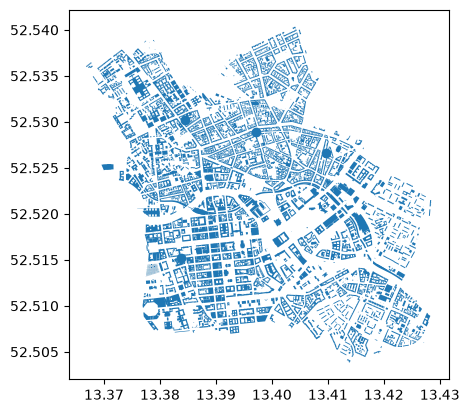

In [1]:
import osmnx as ox
import geopandas as gpd
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

place = " Mitte,Berlin, Germany"

buildings = ox.features_from_place(place, tags={"building": True})

landuse = ox.features_from_place(place, tags={"landuse": True})

parking = ox.features_from_place(place, tags={"amenity": ["parking", "parking_space"]})

roads = ox.features_from_place(place, tags={"highway": True})

print(buildings.shape, landuse.shape, parking.shape, roads.shape)
buildings.plot() 


In [2]:
buildings = buildings.to_crs(epsg=25833)
landuse = landuse.to_crs(epsg=25833)
parking = parking.to_crs(epsg=25833)
roads = roads.to_crs(epsg=25833)

print("buildings geom types before filter:", buildings.geom_type.value_counts().to_dict())
buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

print("parking geom types before filter:", parking.geom_type.value_counts().to_dict())
parking = parking[parking.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

buildings geom types before filter: {'Polygon': 8667, 'Point': 4, 'MultiPolygon': 1}
parking geom types before filter: {'Polygon': 1153, 'Point': 25}


In [3]:
roads["highway"].value_counts()

highway
footway            8243
street_lamp        4135
service            2590
crossing           1556
residential        1553
steps               724
secondary           539
tertiary            533
traffic_signals     438
primary             400
cycleway            225
give_way            211
bus_stop            182
pedestrian          166
platform            158
corridor            112
elevator             79
path                 69
living_street        45
construction         35
traffic_sign         24
stop                 23
unclassified         16
turning_circle        9
secondary_link        3
passing_place         2
speed_camera          2
primary_link          2
mini_roundabout       1
tertiary_link         1
Name: count, dtype: int64

In [4]:

buildings["area_m2"] = buildings.geometry.area

In [5]:
# 3b. Map highway=* values into the paper's 4 road-class buckets, using the paper's EXACT
# tag lists 

def road_bucket(highway_value):
    if highway_value in ["residential", "living_street"]:
        return "residential"
    if highway_value in ["primary", "secondary", "tertiary"]:
        return "highway"
    if highway_value in ["motorway", "trunk"]:
        return "motorway"
    if highway_value in ["service"]:
        return "service"
    return None

roads["bucket"] = roads["highway"].apply(road_bucket)
roads_by_bucket = {b: roads[roads["bucket"] == b] for b in ["residential", "highway", "motorway", "service"]}
{b: len(g) for b, g in roads_by_bucket.items()}

{'residential': 1598, 'highway': 1472, 'motorway': 0, 'service': 2590}

In [6]:
#The 12 road-proximity indicators (4 buckets x 3 buffers: 30/60/90m)
for bucket, sub_roads in roads_by_bucket.items():
    for d in [30, 60, 90]:
        col = f"road_{bucket}_{d}m"
        if sub_roads.empty:
            buildings[col] = 0
            continue
        buffered = buildings.copy()
        buffered["geometry"] = buildings.geometry.buffer(d)
        joined = gpd.sjoin(buffered, sub_roads[["geometry"]], predicate="intersects", how="inner")
        matched_idx = joined.index.unique()
        buildings[col] = buildings.index.isin(matched_idx).astype(int)


buildings.filter(like="road_").sum()

road_residential_30m    3724
road_residential_60m    5193
road_residential_90m    6163
road_highway_30m        2560
road_highway_60m        5032
road_highway_90m        6223
road_motorway_30m          0
road_motorway_60m          0
road_motorway_90m          0
road_service_30m        4350
road_service_60m        5692
road_service_90m        7121
dtype: int64

In [7]:
# 3d. Parking-lot size classing (Fisher-Jenks natural breaks, 3 classes)
import mapclassify

parking["area_m2"] = parking.geometry.area
classifier = mapclassify.FisherJenks(parking["area_m2"], k=3)
parking["size_class"] = classifier.yb  # 0=small, 1=medium, 2=large
parking["size_class"].value_counts()

/home/labdoo/anaconda3/envs/berlin-buildings/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3775: UserWarning: Numba not installed. Using slow pure python version.
  exec(code_obj, self.user_global_ns, self.user_ns)


size_class
0    1082
1      65
2       6
Name: count, dtype: int64

In [8]:
#3e. The 9 parking-proximity indicators (3 buffers x 3 size classes -- same pattern as 3c)
for size_class in [0, 1, 2]:
    sub_parking = parking[parking["size_class"] == size_class]
    for d in [30, 60, 90]:
        col = f"parking_size{size_class}_{d}m"
        if sub_parking.empty:
            buildings[col] = 0
            continue
        buffered = buildings.copy()
        buffered["geometry"] = buildings.geometry.buffer(d)
        joined = gpd.sjoin(buffered, sub_parking[["geometry"]], predicate="intersects", how="inner")
        matched_idx = joined.index.unique()
        buildings[col] = buildings.index.isin(matched_idx).astype(int)


buildings.filter(like="parking_").sum()

parking_size0_30m    2016
parking_size0_60m    4046
parking_size0_90m    6021
parking_size1_30m     350
parking_size1_60m     720
parking_size1_90m    1177
parking_size2_30m      50
parking_size2_60m      82
parking_size2_90m     205
dtype: int64

In [9]:
# 3f. Land-use binary indicators (one column per landuse=* value overlapping the footprint)
import pandas as pd

landuse_joined = gpd.sjoin(buildings[["geometry"]], landuse[["geometry", "landuse"]],
                            predicate="intersects", how="left")
landuse_dummies = pd.get_dummies(landuse_joined["landuse"], prefix="landuse")
landuse_features = landuse_dummies.groupby(landuse_joined.index).max()
landuse_features = landuse_features.reindex(buildings.index).fillna(0).astype(int)
buildings = pd.concat([buildings, landuse_features], axis=1)


buildings.filter(like="landuse_").sum()

landuse_brownfield             25
landuse_cemetery               73
landuse_civic_admin            43
landuse_commercial            987
landuse_construction          101
landuse_education               1
landuse_flowerbed               1
landuse_government              1
landuse_grass                 203
landuse_greenfield              2
landuse_industrial              8
landuse_institutional           6
landuse_meadow                  3
landuse_military               49
landuse_railway                 9
landuse_recreation_ground       4
landuse_religious              14
landuse_residential          4681
landuse_retail                 75
dtype: int64

In [10]:
buildings.columns

Index(['geometry', 'addr:housenumber', 'addr:street', 'building', 'operator',
       'operator:wikidata', 'power', 'ref', 'source', 'name',
       ...
       'landuse_greenfield', 'landuse_industrial', 'landuse_institutional',
       'landuse_meadow', 'landuse_military', 'landuse_railway',
       'landuse_recreation_ground', 'landuse_religious', 'landuse_residential',
       'landuse_retail'],
      dtype='str', length=526)

In [11]:
# 3g. OSM tag presence indicators (binary present/absent).
# 'building' is deliberately excluded -- it's your label source, so including it here
# would be circular (predicting the tag from itself).
tag_cols = ["name", "source", "addr:street", "building:levels", "shop", "website", "brand", "amenity"]
for col in tag_cols:
    buildings[f"has_{col}"] = buildings[col].notna().astype(int) if col in buildings.columns else 0

buildings.filter(like="has_").sum()


has_name                527
has_source              998
has_addr:street        1193
has_building:levels    4725
has_shop                 16
has_website             113
has_brand                23
has_amenity             114
dtype: int64

In [12]:
print(buildings["building"].value_counts().to_string())


building
yes               3634
apartments        2676
residential        698
office             293
commercial         290
roof               135
hospital            76
hotel               75
government          74
university          72
retail              58
house               58
school              56
service             49
civic               33
kindergarten        30
industrial          29
public              22
church              22
viaduct             20
construction        19
embassy             18
container           18
bridge              16
shed                16
garage              16
train_station       15
garages             14
sports_hall         10
museum               8
toilets              8
waste_disposal       8
chapel               7
electricity          6
dormitory            6
theatre              5
sports_centre        4
college              4
tower                4
warehouse            4
transportation       4
elevator             4
guardhouse           3
pa

In [13]:
import urllib.parse

minx, miny, maxx, maxy = buildings.total_bounds  # already in EPSG:25833

params = {
    "service": "WFS",
    "version": "2.0.0",
    "request": "GetFeature",
    "typeNames": "alkis_gebaeude:gebaeude",   # WFS 2.0 requires "typeNames" (plural), not "typeName"
    "outputFormat": "application/json",
    "srsName": "EPSG:25833",
    "bbox": f"{minx},{miny},{maxx},{maxy},EPSG:25833",
}
wfs_url = "https://gdi.berlin.de/services/wfs/alkis_gebaeude?" + urllib.parse.urlencode(params)
alkis = gpd.read_file(wfs_url)
alkis["bezgfk"].value_counts()


bezgfk
Wohnhaus                                       4112
Wohngebäude mit Handel und Dienstleistungen    1211
Gebäude für Wirtschaft oder Gewerbe             804
Tiefgarage                                      471
Bürogebäude                                     359
                                               ... 
Festsaal                                          1
Seniorenfreizeitstätte                            1
Schutzbunker                                      1
Gaswerk                                           1
Kegel-, Bowlinghalle                              1
Name: count, Length: 123, dtype: int64

In [14]:
alkis["bezgfk"].isna().sum()

np.int64(18081)

In [15]:
alkis[alkis["bezgfk"].isna()]["bezbat"].value_counts()


bezbat
Geringergeschossiger Gebäudeteil                          7839
Auskragender Geschossteil / zurückspringendes Geschoss    3880
Durchfahrt im Gebäude                                     3322
Loggia                                                    1060
Hochhausgebäudeteil                                        746
Höhergeschossiger Gebäudeteil (nicht Hochhaus)             614
Keller                                                     449
Schornstein im Gebäude                                      68
Durchfahrt an überbautem Verkehrsweg                        35
Arkade                                                      26
Auskragender Geschossteil                                   25
Zurückspringendes Geschoss                                  15
Turm im Gebäude                                              2
Name: count, dtype: int64

In [16]:
alkis_buildings = alkis[alkis["bezgfk"].notna()].copy()
print(alkis_buildings.shape)


(10043, 27)


In [17]:
print(alkis_buildings["bezgfk"].value_counts().to_string())


bezgfk
Wohnhaus                                                  4112
Wohngebäude mit Handel und Dienstleistungen               1211
Gebäude für Wirtschaft oder Gewerbe                        804
Tiefgarage                                                 471
Bürogebäude                                                359
Garage                                                     214
Verwaltungsgebäude                                         183
Gebäude für Handel und Dienstleistungen                    178
Gebäude für Gewerbe und Industrie                          150
Wohngebäude mit Gewerbe und Industrie                      136
Hotel, Motel, Pension                                      130
Umformer                                                   128
Allgemein bildende Schule                                  114
Lagerhalle, Lagerschuppen, Lagerhaus                       113
Gebäude für Handel und Dienstleistung mit Wohnen           100
Speichergebäude                                 

In [18]:


RESIDENTIAL_BEZGFK = {
    "Wohnhaus", "Wohngebäude", "Wohnheim",
    "Studenten-, Schülerwohnheim", "Schwesternwohnheim",
}

#
EXCLUDED_BEZGFK = {
    # officially mixed residential + non-residential use -- can't force a binary label
    "Wohngebäude mit Handel und Dienstleistungen",
    "Gebäude für Handel und Dienstleistung mit Wohnen",
    "Wohngebäude mit Gewerbe und Industrie",
    "Gemischt genutztes Gebäude mit Wohnen",
    "Wohngebäude mit Gemeinbedarf",
    "Gebäude für Gewerbe und Industrie mit Wohnen",
    "Gebäude für öffentliche Zwecke mit Wohnen",
    # ancillary parking/storage structures -- commonly attached to EITHER residential or
    # commercial parent buildings, so the type itself doesn't disambiguate (paper's Boulder
    # schema explicitly excludes "Garage/Shed" and "Parking Structure" for the same reason)
    "Garage", "Tiefgarage", "Schuppen", "Parkhaus", "Parkdeck", "Gebäude zum Parken", "Gartenhaus",
    # agricultural (paper explicitly excludes "Agricultural")
    "Stall", "Stall im Zoo", "Land- und forstwirtschaftliches Betriebsgebäude",
    "Gebäude für Land- und Forstwirtschaft", "Scheune und Stall", "Treibhaus",
    # ambiguous institutional/residential care -- people live there, but it's institutional
    # care, not a plain dwelling (flagged explicitly in review)
    "Seniorenheim", "Obdachlosenheim", "Kinderheim",
    "Heilanstalt, Pflegeanstalt, Pflegestation", "Kaserne",
    # unspecified / not clearly a building type (paper's "Misc"/"Other" equivalent)
    "Nach Quellenlage nicht zu spezifizieren", "Toilette", "Empfangsgebäude",
    "Wochenendhaus", "Bootshaus",
}

def alkis_label(bezgfk):
    if bezgfk is None:
        return None
    if bezgfk in RESIDENTIAL_BEZGFK:
        return "residential"
    if bezgfk in EXCLUDED_BEZGFK:
        return None
    # Everything else observed in this borough's data is a reviewed, single-use non-dwelling
    # building type (commercial/industrial/institutional/public/religious/education/health/
    # recreation/infrastructure) -- see docs/phase0-taxonomy.md for the full reviewed list.
    return "non_residential"

alkis_buildings["label"] = alkis_buildings["bezgfk"].apply(alkis_label)
alkis_buildings["label"].value_counts(dropna=False)

label
residential        4128
non_residential    3499
NaN                2416
Name: count, dtype: int64

In [19]:
feature_cols = (
    [c for c in buildings.columns if c.startswith("road_")]
    + [c for c in buildings.columns if c.startswith("parking_")]
    + [c for c in buildings.columns if c.startswith("landuse_")]
    + [c for c in buildings.columns if c.startswith("has_")]
    + ["area_m2"]
)

print(len(feature_cols), "base features")


49 base features


In [20]:
# Fix: filter ALKIS to VALID (non-excluded) labels *before* ranking by overlap area --
# otherwise a larger-but-excluded (mixed-use/ambiguous) ALKIS polygon could win the
# "largest overlap" contest over a smaller, validly-labeled neighbor, needlessly discarding
# an OSM building that could have been usefully labeled by its second-best match.
# Also require a minimum overlap ratio so a technically-largest but incidental sliver
# (from OSM/ALKIS digitization misalignment) can't win outright.
alkis_valid = alkis_buildings[alkis_buildings["label"].notna()].copy()

# buildings is already polygon-only (filtered right after reprojection above)
buildings_id = buildings.reset_index(drop=True)
buildings_id["_bid"] = buildings_id.index
buildings_id["_osm_area"] = buildings_id.geometry.area

overlay = gpd.overlay(
    buildings_id[["_bid", "_osm_area", "geometry"]],
    alkis_valid[["geometry", "label"]].rename(columns={"label": "alkis_label"}),
    how="intersection"
)
overlay["overlap_area"] = overlay.geometry.area
overlay["overlap_ratio"] = overlay["overlap_area"] / overlay["_osm_area"]

MIN_OVERLAP_RATIO = 0.5
overlay = overlay[overlay["overlap_ratio"] >= MIN_OVERLAP_RATIO]

best_match = (
    overlay.sort_values("overlap_area", ascending=False)
    .drop_duplicates(subset="_bid")
    .set_index("_bid")["alkis_label"]
)

buildings_id["alkis_label"] = buildings_id["_bid"].map(best_match)
buildings_id["alkis_label"].value_counts(dropna=False)

alkis_label
NaN                3677
residential        2687
non_residential    2304
Name: count, dtype: int64

In [21]:
# Fix: paper uses a FIXED list of 29 common building=* values (verified against paper text --
# one dummy column each) plus a single 'miscellaneous' column for everything else, not a dummy
# per every value observed in this one borough. 
PAPER_BUILDING_VALUES = [
    "apartments", "church", "civic", "commercial", "construction", "detached", "dormitory",
    "garage", "garages", "greenhouse", "hospital", "hotel", "house", "industrial",
    "kindergarten", "office", "parking", "public", "residential", "retail", "roof", "school",
    "semidetached_house", "service", "shed", "static_caravan", "terrace", "warehouse", "yes",
]

building_val = buildings_id["building"].where(
    buildings_id["building"].isin(PAPER_BUILDING_VALUES), "miscellaneous"
)
building_dummies = pd.get_dummies(building_val, prefix="building")

# Re-running this cell must not duplicate columns onto buildings_id from a prior run.
buildings_id = buildings_id.drop(columns=building_dummies.columns, errors="ignore")
buildings_id = pd.concat([buildings_id, building_dummies], axis=1)

feature_cols_v2 = feature_cols + list(building_dummies.columns)

labeled_v2 = buildings_id.dropna(subset=["alkis_label"])
X2 = labeled_v2[feature_cols_v2]
y2 = labeled_v2["alkis_label"]

print(X2.shape, y2.value_counts())

(4991, 77) alkis_label
residential        2687
non_residential    2304
Name: count, dtype: int64


In [22]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)

clf2 = DecisionTreeClassifier(
    class_weight={"non_residential": 2.0, "residential": 1.0},
    min_samples_split=20,
    min_impurity_decrease=0.0001,
    random_state=42,
)
clf2.fit(X2_train, y2_train)
y2_pred = clf2.predict(X2_test)

print("Accuracy:", accuracy_score(y2_test, y2_pred))

print(classification_report(y2_test, y2_pred))

Accuracy: 0.8698698698698699
                 precision    recall  f1-score   support

non_residential       0.85      0.89      0.87       494
    residential       0.89      0.85      0.87       505

       accuracy                           0.87       999
      macro avg       0.87      0.87      0.87       999
   weighted avg       0.87      0.87      0.87       999



In [23]:
pd.Series(clf2.feature_importances_, index=feature_cols_v2).sort_values(ascending=False).head(15)


building_apartments     0.570213
building_residential    0.151151
area_m2                 0.088881
landuse_residential     0.042595
building_house          0.034826
has_building:levels     0.014672
road_service_90m        0.010652
road_residential_30m    0.010045
road_service_30m        0.006895
has_name                0.006871
road_highway_90m        0.006180
building_yes            0.005226
road_highway_60m        0.005152
has_source              0.004439
parking_size0_60m       0.004372
dtype: float64

In [24]:
# === Path C -- accuracy-focused features for Berlin, NOT a paper reproduction ===
# clf2/Path B above is untouched and remains the citable Zhou et al. reproduction.
# This path is free to diverge from the paper's exact tag lists/feature schema wherever
# it plausibly helps Berlin accuracy specifically.

# footway is the single largest highway=* tag in Mitte (8243, more than every vehicle-road
# bucket combined) and the paper's schema has no slot for pedestrian/cycle infrastructure at
# all -- it was built on car-oriented US suburbs. Give it (and cycleway) their own buckets.
def road_bucket_v2(highway_value):
    if highway_value in ["residential", "living_street"]:
        return "residential"
    if highway_value in ["primary", "secondary", "tertiary"]:
        return "highway"
    if highway_value in ["motorway", "trunk"]:
        return "motorway"
    if highway_value in ["service"]:
        return "service"
    if highway_value in ["footway", "path", "pedestrian", "steps", "corridor"]:
        return "pedestrian"
    if highway_value in ["cycleway"]:
        return "cycleway"
    return None

roads["bucket_v2"] = roads["highway"].apply(road_bucket_v2)
roads_by_bucket_v2 = {
    b: roads[roads["bucket_v2"] == b] for b in ["pedestrian", "cycleway"]
}
{b: len(g) for b, g in roads_by_bucket_v2.items()}

{'pedestrian': 9314, 'cycleway': 225}

In [25]:
# Pedestrian/cycleway proximity indicators -- same buffer+sjoin pattern as the existing
# road_/parking_ features, computed directly on buildings_id (the frame that already
# carries alkis_label + Path B's features) so indexing stays consistent for the merge below.
for bucket, sub_roads in roads_by_bucket_v2.items():
    for d in [30, 60, 90]:
        col = f"road_{bucket}_{d}m"
        if sub_roads.empty:
            buildings_id[col] = 0
            continue
        buffered = buildings_id.copy()
        buffered["geometry"] = buildings_id.geometry.buffer(d)
        joined = gpd.sjoin(buffered, sub_roads[["geometry"]], predicate="intersects", how="inner")
        matched_idx = joined.index.unique()
        buildings_id[col] = buildings_id.index.isin(matched_idx).astype(int)

buildings_id.filter(like="road_pedestrian_").sum().to_dict(), buildings_id.filter(like="road_cycleway_").sum().to_dict()

({'road_pedestrian_30m': 8193,
  'road_pedestrian_60m': 8626,
  'road_pedestrian_90m': 8667},
 {'road_cycleway_30m': 722,
  'road_cycleway_60m': 1771,
  'road_cycleway_90m': 2851})

In [26]:
# Numeric building:levels instead of just the has_building:levels presence flag.
# has_building:levels already ranks in the top-15 importances for both clf and clf2 --
# actual floor count likely carries more signal than mere presence (Berlin's uniform
# 4-6 story Altbau residential blocks vs. tall office towers or single-story warehouses).
buildings_id["building_levels_num"] = pd.to_numeric(buildings_id["building:levels"], errors="coerce")
median_levels = buildings_id["building_levels_num"].median()
buildings_id["building_levels_num"] = buildings_id["building_levels_num"].fillna(median_levels)

# Footprint compactness (Polsby-Popper shape index: 4*pi*area/perimeter^2, in (0,1], 1=circle).
# Cheap to compute from geometry already in hand, no new data fetch. Building shape is a
# classic residential-vs-commercial/industrial signal the paper's schema doesn't use at all --
# large simple-footprint warehouses/big-box retail score very differently from Berlin's
# Blockrand residential buildings or small detached houses.
buildings_id["perimeter_m"] = buildings_id.geometry.length
buildings_id["compactness"] = (4 * 3.14159265 * buildings_id["_osm_area"]) / (buildings_id["perimeter_m"] ** 2)

buildings_id[["building_levels_num", "compactness"]].describe()

,building_levels_num,compactness
count,8668.000000,8668.000000
mean,4.837102,0.594183
std,1.799500,0.155356
min,0.000000,0.016695
25%,5.000000,0.504155
50%,5.000000,0.649615
75%,5.000000,0.693033
max,33.000000,0.997590


In [27]:
feature_cols_v3 = feature_cols_v2 + [
    "road_pedestrian_30m", "road_pedestrian_60m", "road_pedestrian_90m",
    "road_cycleway_30m", "road_cycleway_60m", "road_cycleway_90m",
    "building_levels_num", "compactness",
]

# Same dropna(alkis_label) filter as Path B, so labeled_v3 covers the same rows as
# labeled_v2 -- combined with the same random_state=42 split below, this makes clf3 vs
# clf2 a clean apples-to-apples comparison (identical train/test rows, only features differ).
labeled_v3 = buildings_id.dropna(subset=["alkis_label"])
X3 = labeled_v3[feature_cols_v3]
y3 = labeled_v3["alkis_label"]

X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42)

clf3 = DecisionTreeClassifier(
    class_weight={"non_residential": 2.0, "residential": 1.0},
    min_samples_split=20,
    min_impurity_decrease=0.0001,
    random_state=42,
)
clf3.fit(X3_train, y3_train)
y3_pred = clf3.predict(X3_test)

print("Path C accuracy:", accuracy_score(y3_test, y3_pred))
print(classification_report(y3_test, y3_pred))
print("\nPath B (clf2) accuracy was:", accuracy_score(y2_test, y2_pred))

Path C accuracy: 0.8668668668668669
                 precision    recall  f1-score   support

non_residential       0.84      0.90      0.87       494
    residential       0.90      0.83      0.86       505

       accuracy                           0.87       999
      macro avg       0.87      0.87      0.87       999
   weighted avg       0.87      0.87      0.87       999


Path B (clf2) accuracy was: 0.8698698698698699


In [28]:
pd.Series(clf3.feature_importances_, index=feature_cols_v3).sort_values(ascending=False).head(20)

building_apartments     0.540014
building_residential    0.143146
area_m2                 0.063796
compactness             0.041907
landuse_residential     0.040339
building_house          0.032982
building_levels_num     0.021413
has_building:levels     0.013928
road_service_90m        0.010572
road_cycleway_90m       0.009222
has_name                0.007439
road_residential_30m    0.005670
road_highway_90m        0.005351
building_yes            0.004949
parking_size0_60m       0.004034
road_service_60m        0.004023
road_service_30m        0.003684
landuse_religious       0.003675
road_pedestrian_30m     0.003577
landuse_construction    0.003560
dtype: float64

In [29]:
# A single 80/20 split on ~1000 test rows is noisy (std err on a proportion at 87%,
# n=999 is ~1.1pp) -- the 0.3pp clf2-vs-clf3 gap seen above isn't trustworthy either way.
# 5-fold CV on the full labeled set gives a much more reliable read before deciding whether
# the pedestrian buckets actually hurt or whether that was just split noise.
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cv_score(X, y, label):
    clf = DecisionTreeClassifier(
        class_weight={"non_residential": 2.0, "residential": 1.0},
        min_samples_split=20,
        min_impurity_decrease=0.0001,
        random_state=42,
    )
    scores = cross_validate(clf, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    print(f"{label}: accuracy {scores['test_accuracy'].mean():.4f} +/- {scores['test_accuracy'].std():.4f}"
          f"  |  macro-F1 {scores['test_f1_macro'].mean():.4f} +/- {scores['test_f1_macro'].std():.4f}")
    print("  per-fold accuracy:", scores["test_accuracy"].round(4).tolist())
    return scores

scores_b = cv_score(X2, y2, "Path B (clf2, 77 features)")
scores_c = cv_score(X3, y3, "Path C (clf3, 85 features, w/ pedestrian buckets)")

Path B (clf2, 77 features): accuracy 0.8732 +/- 0.0082  |  macro-F1 0.8729 +/- 0.0081
  per-fold accuracy: [0.8779, 0.8788, 0.8798, 0.8717, 0.8577]


Path C (clf3, 85 features, w/ pedestrian buckets): accuracy 0.8686 +/- 0.0081  |  macro-F1 0.8682 +/- 0.0080
  per-fold accuracy: [0.8779, 0.8657, 0.8768, 0.8667, 0.8557]


In [30]:
# Third variant: same as Path C but with the near-saturated pedestrian buckets dropped
# (road_pedestrian_30/60/90m -- 94%+ of buildings fall inside even the 30m buffer in dense
# Mitte, so they're close to constant and don't discriminate). Keeps compactness,
# building_levels_num, and the cycleway buckets (much sparser, showed real importance).
feature_cols_v3_trimmed = [c for c in feature_cols_v3 if not c.startswith("road_pedestrian_")]
X3_trimmed = labeled_v3[feature_cols_v3_trimmed]

scores_c_trimmed = cv_score(X3_trimmed, y3, "Path C trimmed (82 features, no pedestrian buckets)")

Path C trimmed (82 features, no pedestrian buckets): accuracy 0.8690 +/- 0.0100  |  macro-F1 0.8687 +/- 0.0098
  per-fold accuracy: [0.8789, 0.8677, 0.8788, 0.8677, 0.8517]


In [31]:
# Path C came in slightly below Path B under CV, but the paper's min_samples_split=20 /
# min_impurity_decrease=0.0001 were tuned for a 77-feature space, not this 82-85 feature
# one -- more candidate splits per node without re-tuning the regularizer is a plausible
# reason extra features hurt rather than helped. Sweep both feature sets over the same grid
# before concluding the *features* (not the fixed hyperparameters) are the problem.
from sklearn.model_selection import GridSearchCV

param_grid = {
    "min_samples_split": [10, 20, 40, 80],
    "min_impurity_decrease": [0.0, 0.0001, 0.0005, 0.001],
}

def best_cv_score(X, y, label):
    base = DecisionTreeClassifier(class_weight={"non_residential": 2.0, "residential": 1.0}, random_state=42)
    search = GridSearchCV(base, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X, y)
    print(f"{label}: best macro-F1 {search.best_score_:.4f}  |  best params {search.best_params_}")
    return search

search_b = best_cv_score(X2, y2, "Path B (77 features)")
search_c = best_cv_score(X3_trimmed, y3, "Path C trimmed (82 features)")
search_c_full = best_cv_score(X3, y3, "Path C full (85 features)")

Path B (77 features): best macro-F1 0.8911  |  best params {'min_impurity_decrease': 0.001, 'min_samples_split': 80}


Path C trimmed (82 features): best macro-F1 0.8893  |  best params {'min_impurity_decrease': 0.001, 'min_samples_split': 10}


Path C full (85 features): best macro-F1 0.8893  |  best params {'min_impurity_decrease': 0.001, 'min_samples_split': 10}
